In [3]:
import torch, pandas as pd

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
indian = pd.read_csv("indian_test_set.csv")

print(len(train_df), len(val_df), len(indian))
print(train_df.columns.tolist())

GPU available: True
Tesla T4
3618 775 100
['label', 'text', 'length', 'y', 'clean']


In [4]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset

MODEL = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

class SMSData(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding=True, max_length=128)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

train_ds = SMSData(train_df["text"], train_df["y"])
val_ds = SMSData(val_df["text"], val_df["y"])
ind_ds = SMSData(indian["text"], indian["label"])
print(len(train_ds), len(val_ds), len(ind_ds))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

3618 775 100


In [5]:
import numpy as np
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    pr, rc, f1, _ = precision_recall_fscore_support(
        p.label_ids, preds, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "precision": pr, "recall": rc, "f1": f1}

args = TrainingArguments(
    output_dir="distilbert_out",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds,
                  eval_dataset=val_ds, compute_metrics=compute_metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.079494,0.058093,0.989677,0.989130,0.928571,0.957895
2,0.036363,0.046966,0.988387,0.978495,0.928571,0.952880
3,0.004822,0.051750,0.985806,0.957895,0.928571,0.943005


TrainOutput(global_step=681, training_loss=0.04599744094625969, metrics={'train_runtime': 39.6523, 'train_samples_per_second': 273.729, 'train_steps_per_second': 17.174, 'total_flos': 359450286253056.0, 'train_loss': 0.04599744094625969, 'epoch': 3.0})

              precision    recall  f1-score   support

       legit      0.308     0.080     0.127        50
        spam      0.471     0.820     0.599        50

    accuracy                          0.450       100
   macro avg      0.389     0.450     0.363       100
weighted avg      0.389     0.450     0.363       100



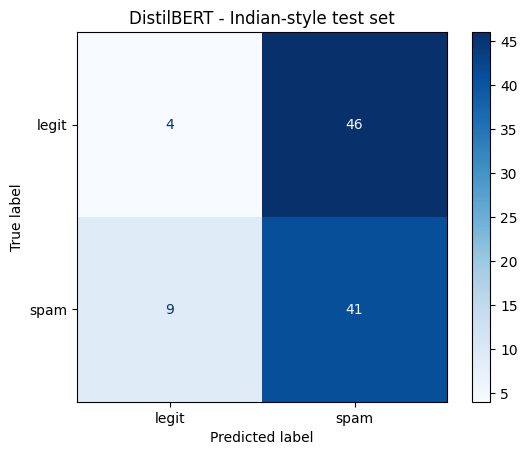

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

out = trainer.predict(ind_ds)
ind_pred = np.argmax(out.predictions, axis=1)

print(classification_report(indian["label"], ind_pred, target_names=["legit", "spam"], digits=3))
cm = confusion_matrix(indian["label"], ind_pred)
ConfusionMatrixDisplay(cm, display_labels=["legit", "spam"]).plot(cmap="Blues")
plt.title("DistilBERT - Indian-style test set"); plt.show()

In [7]:
import re
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def clean(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " urltoken ", t)
    t = re.sub(r"\b\d{10,}\b", " phonetoken ", t)
    t = re.sub(r"[\u20b9$\u00a3]\s?\d[\d,\.]*|\brs\.?\s?\d[\d,\.]*", " moneytoken ", t)
    t = re.sub(r"\d+", " numtoken ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

indian["y"] = indian["label"]
indian["clean"] = indian["text"].apply(clean)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def run_cv(repeat):
    true, pred = [], []
    for tr_idx, te_idx in skf.split(indian, indian["y"]):
        ind_tr, ind_te = indian.iloc[tr_idx], indian.iloc[te_idx]
        tr = pd.concat([train_df[["clean", "y"]]] + [ind_tr[["clean", "y"]]] * repeat)
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
        clf.fit(vec.fit_transform(tr["clean"]), tr["y"])
        true += ind_te["y"].tolist()
        pred += clf.predict(vec.transform(ind_te["clean"])).tolist()
    p, r, f, _ = precision_recall_fscore_support(true, pred, average="binary", zero_division=0)
    return round(accuracy_score(true, pred), 3), round(p, 3), round(r, 3), round(f, 3)

print("copies of Indian examples | accuracy, precision, recall, F1")
for rep in [0, 1, 5, 10]:
    print(rep, "|", run_cv(rep))

copies of Indian examples | accuracy, precision, recall, F1
0 | (0.51, 0.508, 0.6, 0.55)
1 | (0.67, 0.627, 0.84, 0.718)
5 | (0.79, 0.738, 0.9, 0.811)
10 | (0.84, 0.804, 0.9, 0.849)


In [9]:
import numpy as np, torch
from torch.utils.data import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

MODEL = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

class SMSData(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding=True, max_length=128)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

def run_bert_cv(repeat=5):
    true, pred = [], []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(indian, indian["y"])):
        ind_tr, ind_te = indian.iloc[tr_idx], indian.iloc[te_idx]
        texts = list(train_df["text"]) + list(ind_tr["text"]) * repeat
        labels = list(train_df["y"]) + list(ind_tr["y"]) * repeat
        model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)
        args = TrainingArguments(output_dir="cv_out", num_train_epochs=3,
            per_device_train_batch_size=16, learning_rate=2e-5, weight_decay=0.01,
            save_strategy="no", eval_strategy="no", fp16=True, seed=42,
            report_to="none", logging_steps=1000)
        trainer = Trainer(model=model, args=args, train_dataset=SMSData(texts, labels))
        trainer.train()
        out = trainer.predict(SMSData(ind_te["text"], ind_te["y"]))
        true += ind_te["y"].tolist()
        pred += np.argmax(out.predictions, axis=1).tolist()
        print("fold", fold + 1, "done")
    p, r, f, _ = precision_recall_fscore_support(true, pred, average="binary", zero_division=0)
    return round(accuracy_score(true, pred), 3), round(p, 3), round(r, 3), round(f, 3)

print("DistilBERT, 5 copies | accuracy, precision, recall, F1")
print(run_bert_cv(5))

DistilBERT, 5 copies | accuracy, precision, recall, F1


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


fold 1 done


...

fold 4 done


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


fold 5 done
(0.81, 0.782, 0.86, 0.819)
